In [1]:
#
# %pip install pandas

In [2]:
import sys
import numpy as np
import matplotlib

print("Python executable:", sys.executable)
print("Python version   :", sys.version.split()[0])
print("NumPy            :", np.__version__)
print("Matplotlib       :", matplotlib.__version__)

Python executable: g:\sen2fire-thesis\.venv\Scripts\python.exe
Python version   : 3.12.10
NumPy            : 2.5.4
Matplotlib       : 3.11.2


In [3]:
from pathlib import Path
import zipfile
from collections import Counter

PROJECT_DIR = Path.cwd()
ZIP_PATH = PROJECT_DIR / "data" / "raw" / "Sen2Fire.zip"

print("Working directory:", PROJECT_DIR)
print("Zip exists       :", ZIP_PATH.exists())

with zipfile.ZipFile(ZIP_PATH) as zf:
    names = zf.namelist()
    infos = zf.infolist()

print("Total entries    :", len(names))
print("First 8 entries  :")
for n in names[:8]:
    print("  ", n)

top_levels = Counter(n.split("/")[0] for n in names)
print("Top-level folders:", dict(top_levels))

ext_counts = Counter(Path(n).suffix.lower() for n in names if not n.endswith("/"))
print("File extensions  :", dict(ext_counts))

total_gb = sum(i.file_size for i in infos) / 1e9
print(f"Uncompressed size: {total_gb:.2f} GB")

Working directory: g:\sen2fire-thesis
Zip exists       : True
Total entries    : 2466
First 8 entries  :
   scene1/scene_1_patch_1_1.npz
   scene1/scene_1_patch_1_10.npz
   scene1/scene_1_patch_1_11.npz
   scene1/scene_1_patch_1_12.npz
   scene1/scene_1_patch_1_13.npz
   scene1/scene_1_patch_1_14.npz
   scene1/scene_1_patch_1_15.npz
   scene1/scene_1_patch_1_16.npz
Top-level folders: {'scene1': 864, 'scene2': 594, 'scene3': 504, 'scene4': 504}
File extensions  : {'.npz': 2466}
Uncompressed size: 6.37 GB


In [4]:
import time

EXTRACT_DIR = PROJECT_DIR / "data" / "sen2fire"

if EXTRACT_DIR.exists() and any(EXTRACT_DIR.rglob("*.npz")):
    print("Already extracted, skipping.")
else:
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    t0 = time.perf_counter()
    with zipfile.ZipFile(ZIP_PATH) as zf:
        zf.extractall(EXTRACT_DIR)
    print(f"Extracted in {time.perf_counter() - t0:.1f} s")

for scene in ["scene1", "scene2", "scene3", "scene4"]:
    n = len(list((EXTRACT_DIR / scene).glob("*.npz")))
    print(f"{scene}: {n} files")

Already extracted, skipping.
scene1: 864 files
scene2: 594 files
scene3: 504 files
scene4: 504 files


In [5]:
import numpy as np

patch_path = EXTRACT_DIR / "scene1" / "scene_1_patch_1_1.npz"
print("File:", patch_path.name)
print(f"Size on disk: {patch_path.stat().st_size / 1e6:.2f} MB")

with np.load(patch_path) as data:
    print("Keys:", list(data.keys()))
    print()
    for key in data.keys():
        arr = data[key]
        print(f"{key:10s} shape={arr.shape}  dtype={arr.dtype}  "
              f"min={arr.min():.4g}  max={arr.max():.4g}  mean={arr.mean():.4g}")

File: scene_1_patch_1_1.npz
Size on disk: 2.68 MB
Keys: ['image', 'aerosol', 'label']

image      shape=(12, 512, 512)  dtype=int16  min=170  max=6181  mean=1946
aerosol    shape=(512, 512)  dtype=float32  min=-1.162  max=-0.2821  mean=-1.083
label      shape=(512, 512)  dtype=uint8  min=0  max=0  mean=0


In [6]:
with np.load(patch_path) as data:
    img = data["image"].astype(np.float32)

print(f"{'idx':>3} {'min':>8} {'mean':>8} {'max':>8} {'std':>8}")
for i in range(img.shape[0]):
    b = img[i]
    print(f"{i:>3} {b.min():8.0f} {b.mean():8.0f} {b.max():8.0f} {b.std():8.0f}")

idx      min     mean      max      std
  0      213      610     1985      173
  1      170      773     5064      257
  2      265      977     4952      300
  3      230     1307     4508      412
  4      663     1565     4583      369
  5     1047     1862     4652      295
  6     1030     2069     4789      301
  7      391     2300     5080      348
  8     1021     2404     4874      325
  9     1651     2434     4200      295
 10     1824     4013     6181      815
 11     1054     3042     5345      881


In [7]:
import time

t0 = time.perf_counter()
records = []
label_values = set()

for scene in ["scene1", "scene2", "scene3", "scene4"]:
    for p in sorted((EXTRACT_DIR / scene).glob("*.npz")):
        with np.load(p) as d:
            lab = d["label"]
        label_values.update(np.unique(lab).tolist())
        records.append((scene, p.name, int((lab > 0).sum())))

print(f"Scan took {time.perf_counter() - t0:.1f} s")
print("Unique label values found:", sorted(label_values))
print()

print(f"{'scene':8s} {'patches':>8s} {'with fire':>10s} {'fire px':>10s} {'fire px %':>10s}")
for scene in ["scene1", "scene2", "scene3", "scene4"]:
    rs = [r for r in records if r[0] == scene]
    n_fire = sum(r[2] > 0 for r in rs)
    px = sum(r[2] for r in rs)
    print(f"{scene:8s} {len(rs):8d} {n_fire:10d} {px:10d} {100*px/(len(rs)*512*512):10.4f}")

print()
print("Top 5 patches by fire pixels:")
for r in sorted(records, key=lambda r: r[2], reverse=True)[:5]:
    print(" ", r)

Scan took 7.9 s
Unique label values found: [0, 1]

scene     patches  with fire    fire px  fire px %
scene1        864        115    7779854     3.4349
scene2        594         38    1784143     1.1458
scene3        504         94    4694012     3.5528
scene4        504        102    7632679     5.7771

Top 5 patches by fire pixels:
  ('scene1', 'scene_1_patch_8_14.npz', 257475)
  ('scene1', 'scene_1_patch_9_14.npz', 253135)
  ('scene1', 'scene_1_patch_9_15.npz', 251399)
  ('scene4', 'scene_4_patch_19_13.npz', 242047)
  ('scene4', 'scene_4_patch_7_11.npz', 234169)


Chosen patch: ('scene3', 'scene_3_patch_3_24.npz', 9940)


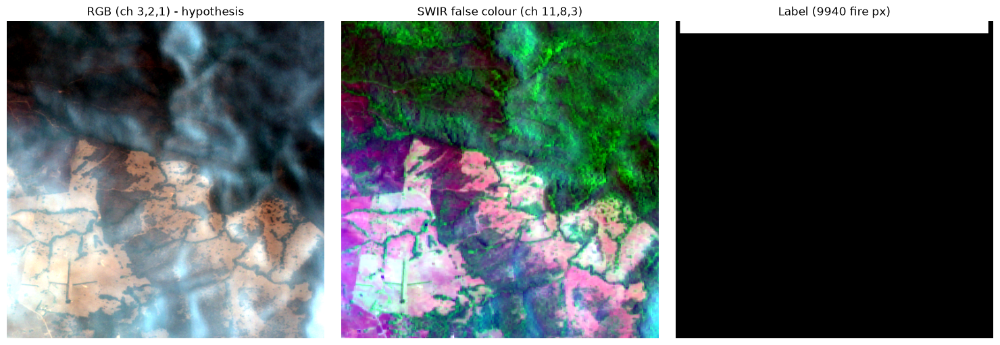


 ch  fire mean   non-fire   ratio
  0       1388       1628    0.85
  1       1252       1527    0.82
  2       1137       1426    0.80
  3        895       1258    0.71
  4       1147       1483    0.77
  5       1761       1914    0.92
  6       1967       2088    0.94
  7       2041       2170    0.94
  8       2159       2296    0.94
  9       2266       2345    0.97
 10       1410       2302    0.61
 11        720       1522    0.47


In [8]:
import matplotlib.pyplot as plt

fire_records = [r for r in records if r[2] > 0]
pick = min(fire_records, key=lambda r: abs(r[2] - 10_000))
print("Chosen patch:", pick)

with np.load(EXTRACT_DIR / pick[0] / pick[1]) as d:
    img = d["image"].astype(np.float32)
    lab = d["label"]

def stretch(rgb):
    out = np.zeros_like(rgb)
    for c in range(3):
        lo, hi = np.percentile(rgb[..., c], [2, 98])
        out[..., c] = np.clip((rgb[..., c] - lo) / (hi - lo + 1e-6), 0, 1)
    return out

rgb = stretch(np.stack([img[3], img[2], img[1]], axis=-1))
swir = stretch(np.stack([img[11], img[8], img[3]], axis=-1))

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(rgb);  ax[0].set_title("RGB (ch 3,2,1) - hypothesis")
ax[1].imshow(swir); ax[1].set_title("SWIR false colour (ch 11,8,3)")
ax[2].imshow(lab, cmap="gray"); ax[2].set_title(f"Label ({int(lab.sum())} fire px)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

fire = lab > 0
print(f"\n{'ch':>3} {'fire mean':>10} {'non-fire':>10} {'ratio':>7}")
for i in range(img.shape[0]):
    f, n = img[i][fire].mean(), img[i][~fire].mean()
    print(f"{i:>3} {f:10.0f} {n:10.0f} {f/n:7.2f}")

In [9]:
rows = np.where(lab.any(axis=1))[0]
cols = np.where(lab.any(axis=0))[0]
print(f"Fire rows   : {rows.min()} to {rows.max()}  ({len(rows)} rows)")
print(f"Fire columns: {cols.min()} to {cols.max()}  ({len(cols)} cols)")
bbox_area = len(rows) * len(cols)
print(f"Bounding box area: {bbox_area}  |  fire px: {int(lab.sum())}  |  fill: {lab.sum()/bbox_area:.3f}")

near = np.zeros_like(lab, dtype=bool)
near[rows.max() + 1 : rows.max() + 1 + 30, :] = True
fire = lab > 0

print(f"\nFire pixels vs the 30 rows directly below them")
print(f"{'ch':>3} {'fire':>8} {'nearby':>8} {'ratio':>7}")
for i in range(img.shape[0]):
    f, n = img[i][fire].mean(), img[i][near].mean()
    print(f"{i:>3} {f:8.0f} {n:8.0f} {f/n:7.2f}")

Fire rows   : 0 to 19  (20 rows)
Fire columns: 7 to 503  (497 cols)
Bounding box area: 9940  |  fire px: 9940  |  fill: 1.000

Fire pixels vs the 30 rows directly below them
 ch     fire   nearby   ratio
  0     1388     1397    0.99
  1     1252     1259    0.99
  2     1137     1143    0.99
  3      895      895    1.00
  4     1147     1145    1.00
  5     1761     1753    1.00
  6     1967     1955    1.01
  7     2041     2026    1.01
  8     2159     2144    1.01
  9     2266     2237    1.01
 10     1410     1400    1.01
 11      720      713    1.01


In [10]:
rng = np.random.default_rng(0)
idx = rng.choice(len(fire_records), size=60, replace=False)
sample = [fire_records[i] for i in idx]

ratios, fills = [], []
t0 = time.perf_counter()
for scene, name, npx in sample:
    with np.load(EXTRACT_DIR / scene / name) as d:
        im = d["image"].astype(np.float32)
        lb = d["label"] > 0
    if lb.all():
        continue
    ratios.append([im[c][lb].mean() / im[c][~lb].mean() for c in range(12)])
    r, c_ = np.where(lb.any(axis=1))[0], np.where(lb.any(axis=0))[0]
    fills.append(lb.sum() / (len(r) * len(c_)))

ratios = np.array(ratios)
fills = np.array(fills)
print(f"Patches used: {len(ratios)}  ({time.perf_counter() - t0:.1f} s)")

print(f"\n{'ch':>3} {'median':>8} {'p25':>7} {'p75':>7} {'% >1':>6}")
for c in range(12):
    col = ratios[:, c]
    print(f"{c:>3} {np.median(col):8.2f} {np.percentile(col,25):7.2f} "
          f"{np.percentile(col,75):7.2f} {100*(col>1).mean():6.0f}")

print(f"\nBounding-box fill: median={np.median(fills):.3f}, "
      f"share of patches with fill > 0.99: {100*(fills>0.99).mean():.0f}%")

Patches used: 60  (2.6 s)

 ch   median     p25     p75   % >1
  0     1.01    0.90    1.14     53
  1     1.01    0.90    1.16     53
  2     1.00    0.90    1.13     50
  3     0.98    0.84    1.09     45
  4     0.97    0.90    1.08     43
  5     0.98    0.95    1.07     42
  6     0.99    0.95    1.05     42
  7     0.98    0.95    1.04     38
  8     0.98    0.95    1.03     38
  9     0.98    0.94    1.03     38
 10     0.91    0.83    1.03     30
 11     0.97    0.81    1.10     47

Bounding-box fill: median=0.948, share of patches with fill > 0.99: 45%


In [11]:
REF_ZIP = PROJECT_DIR / "data" / "reference" / "Baseline_code.zip"
REF_ZIP.parent.mkdir(parents=True, exist_ok=True)
print("Folder ready :", REF_ZIP.parent)
print("Zip present  :", REF_ZIP.exists())

if REF_ZIP.exists():
    with zipfile.ZipFile(REF_ZIP) as zf:
        for info in zf.infolist():
            print(f"{info.file_size:>10,d}  {info.filename}")

Folder ready : g:\sen2fire-thesis\data\reference
Zip present  : True
         0  dataset/__init__.py
     7,083  dataset/Sen2Fire_Dataset.py
    15,721  dataset/test.txt
    45,682  dataset/train.txt
    15,676  dataset/val.txt
         0  model/__init__.py
     3,157  model/Networks.py
     8,301  Test.py
    13,787  Train.py
         0  utils/__init__.py
     2,769  utils/tools.py


In [12]:
with zipfile.ZipFile(REF_ZIP) as zf:
    text = zf.read("dataset/Sen2Fire_Dataset.py").decode("utf-8", errors="replace")

for n, line in enumerate(text.splitlines(), start=1):
    print(f"{n:3d}  {line}")

  1  import os.path as osp
  2  import numpy as np
  3  from torch.utils import data
  4  from tqdm import tqdm
  5  
  6  modename = ['all_bands',                        #0
  7              'all_bands_aerosol',                #1
  8              'rgb',                              #2
  9              'rgb_aerosol',                      #3
 10              'swir',                             #4
 11              'swir_aerosol',                     #5
 12              'nbr',                              #6
 13              'nbr_aerosol',                      #7   
 14              'ndvi',                             #8
 15              'ndvi_aerosol',                     #9 
 16              'rgb_swir_nbr_ndvi',                #10
 17              'rgb_swir_nbr_ndvi_aerosol',]       #11
 18  
 19  Max_values = np.array([4.58500000e+03, 8.96800000e+03, 1.03440000e+04, 1.01840000e+04,
 20                        1.67280000e+04, 1.65260000e+04, 1.63650000e+04, 1.31360000e+04,
 21            

# Sen2Fire - data audit notes

## Verified by me
- Source: Zenodo record 10881058, `Sen2Fire.zip`, MD5 matches published value.
- 2,466 `.npz` patches: scene1=864, scene2=594, scene3=504, scene4=504.
- Each file has keys `image` (12,512,512 int16), `aerosol` (512,512 float32), `label` (512,512 uint8, values 0/1).
- 349 patches contain fire (14%). Fire pixels: ~3.4% overall; scenes 1+2 ~2.5%, scene 3 ~3.55%, scene 4 ~5.78%.
- Label masks are often clean rectangles (45% of sampled fire patches: bounding-box fill > 0.99).
- - Visual check of 6 random fire patches (SWIR composite, channels 11/7/3): 4 show clear orange-red fire fronts. Labels are blocky, stair-stepped outlines that cover the fire plus much unburnt surrounding area. Averages inside labels therefore show little SWIR contrast (dilution), but the fire is real.
- 2 of 6 patches (scene_4_patch_14_5, scene_1_patch_20_8) show no obvious fire inside the label; cause unknown.
- Channel 11 behaves like a SWIR band (fire fronts appear orange-red in the 11/7/3 composite)..

## From the authors' baseline code (not independently verified)
- Image is divided by 10,000 to give reflectance.
- RGB = channels 3,2,1. NIR = channel 7. SWIR (B12-like) = channel 11. Red = channel 3.
- Aerosol is appended as the last (13th) channel.

## Still unknown / to check
- Identity of channels 0, 4, 5, 6, 8, 9, 10 (assumed standard L2A order, B8A = 8).
- Whether the official train/val/test lists match the scene folders.
- Meaning and units of the aerosol values.


## Notes

- Spectral evidence: B12/B11 > 1 separates flaming pixels from bright bare ground (ground median ratio ~0.6-0.7). On 60 sampled fire patches, B12>0.3 & ratio>1.0 gives precision 0.65 but recall 0.018. Hot pixels total <=7% of label pixels, so pixel-level IoU of any spectral rule is capped at a few percent.
- ~1/3 of hot pixels fall outside labels (examples: scene_3 patches 10_2, 10_34); cause unknown.
- Thresholds above were chosen on the same 60 patches: exploratory only.
- Baseline v1 (spectral threshold rule, tuned on train scenes only, frozen in results/frozen_rule_v1.json):
  patch is "fire" if >=200 pixels have B12>=0.24 and B12/B11>=1.45.
  Train patch F1 0.603; val patch F1 0.667 (precision 0.757, recall 0.596; flag-all F1 0.314).
- Pixel level (B12>=0.10, ratio>=1.15), val: precision 0.508, recall 0.035, F1 0.066, IoU 0.034;
  flag-all F1 = 0.069. Precision is ~14x the base rate, but hot pixels cover only ~3.5% of label area.
- F1 optimum at k=200 is interior (k=300..5000 decrease monotonically). F1 plateau across B12/ratio settings.
- Test scene not yet touched. Rule is frozen; evaluate once, together with the learned models.

- Recall of frozen rule on train fire patches by label size: <5,000 px: 0/20 (median hot px 0);
  5,000-20,000 px: 12/33 (0.36, median hot px 6); >20,000 px: 58/100 (0.58, median 596).
  => Threshold baseline misses fires whose labels have no visible B11/B12 hot pixels.
- Train false alarms: 9 of 1,305 non-fire patches (0.7%), median 320 hot px (possibly unlabelled fire; unchecked).
- Baseline results saved: results/baseline_threshold_results.csv, results/frozen_rule_v1.json.

In [13]:
splits = {}
with zipfile.ZipFile(REF_ZIP) as zf:
    for name in ["train", "val", "test"]:
        raw = zf.read(f"dataset/{name}.txt").decode("utf-8")
        splits[name] = [line.strip() for line in raw.splitlines() if line.strip()]

for name, items in splits.items():
    scenes = sorted({Path(i).parts[0] if len(Path(i).parts) > 1 else "(no folder)" for i in items})
    print(f"{name:5s}: {len(items):5d} entries | first: {items[0]} | folders: {scenes}")

all_on_disk = {f"{s}/{p.name}" for s in ["scene1", "scene2", "scene3", "scene4"]
               for p in (EXTRACT_DIR / s).glob("*.npz")}

for name, items in splits.items():
    norm = [i.replace("\\", "/") for i in items]
    missing = [i for i in norm if i not in all_on_disk]
    print(f"{name:5s}: missing on disk = {len(missing)}", missing[:3])

sets = {k: {i.replace("\\", "/") for i in v} for k, v in splits.items()}
print("train & val overlap :", len(sets["train"] & sets["val"]))
print("train & test overlap:", len(sets["train"] & sets["test"]))
print("val & test overlap  :", len(sets["val"] & sets["test"]))
print("on disk but in no split:", len(all_on_disk - sets["train"] - sets["val"] - sets["test"]))

train:  1458 entries | first: scene1/scene_1_patch_1_1.npz | folders: ['scene1', 'scene2']
val  :   504 entries | first: scene3/scene_3_patch_1_1.npz | folders: ['scene3']
test :   504 entries | first: scene4/scene_4_patch_1_1.npz | folders: ['scene4']
train: missing on disk = 0 []
val  : missing on disk = 0 []
test : missing on disk = 0 []
train & val overlap : 0
train & test overlap: 0
val & test overlap  : 0
on disk but in no split: 0


In [14]:
import subprocess, sys

freeze = subprocess.run(
    [sys.executable, "-m", "pip", "freeze"],
    capture_output=True, text=True, check=True
).stdout

(PROJECT_DIR / "requirements.txt").write_text(freeze)
(PROJECT_DIR / ".gitignore").write_text(".venv/\ndata/\n__pycache__/\n.ipynb_checkpoints/\n")

print(freeze)
print("Python:", sys.version.split()[0])
print("Files in project root:", sorted(p.name for p in PROJECT_DIR.iterdir()))

asttokens==3.0.2
colorama==0.4.6
comm==0.2.3
contourpy==1.4.0
cycler==0.12.1
debugpy==1.8.22
executing==2.3.0
fonttools==4.67.0
ipykernel==7.4.0
ipython==9.17.1
ipython_pygments_lexers==1.1.1
jedi==0.20.1
jupyter_client==8.10.0
jupyter_core==5.9.1
kiwisolver==1.5.1
matplotlib==3.11.2
matplotlib-inline==0.2.2
nest-asyncio2==1.7.4
numpy==2.5.4
packaging==26.3
pandas==3.1.0
parso==0.8.7
pillow==13.0.0
platformdirs==4.13.5
prompt_toolkit==3.0.53
psutil==7.2.2
pure_eval==0.2.4
Pygments==2.21.0
pyparsing==3.3.3
python-dateutil==3.0.0
pyzmq==27.2.0
six==1.17.0
stack-data==0.6.3
tornado==6.6
traitlets==5.16.1
typing_extensions==4.16.0
tzdata==2026.5
wcwidth==0.9.3

Python: 3.12.10
Files in project root: ['.gitignore', '.venv', '01_data_inspection.ipynb', '02_baseline_threshold.ipynb', 'data', 'requirements.txt', 'results']


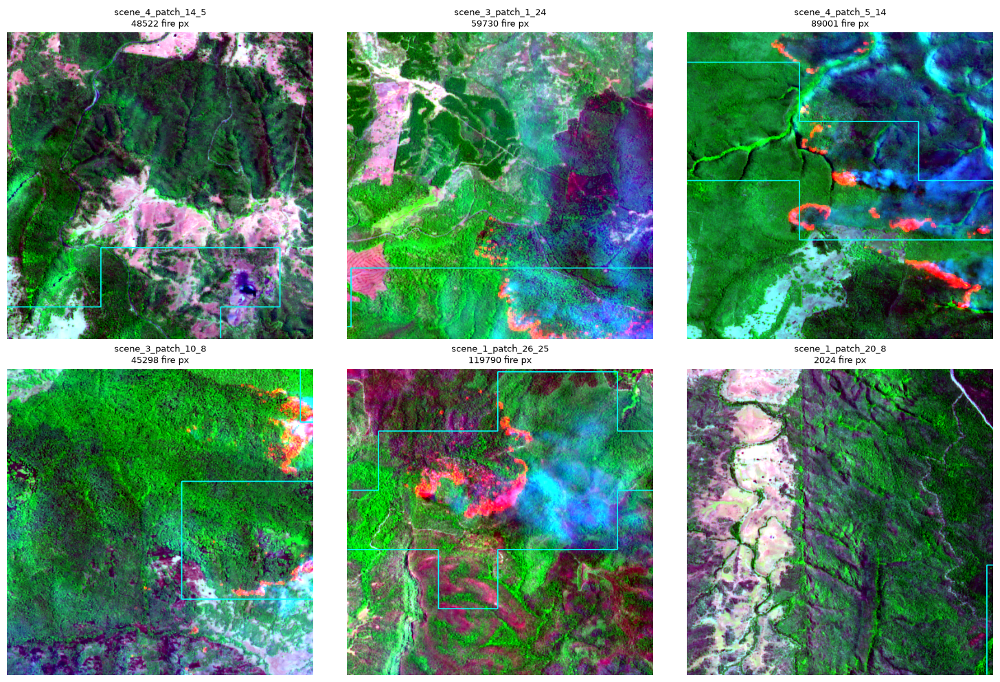

In [15]:
rng2 = np.random.default_rng(1)
picks = [fire_records[i] for i in rng2.choice(len(fire_records), size=6, replace=False)]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, (scene, name, npx) in zip(axes.ravel(), picks):
    with np.load(EXTRACT_DIR / scene / name) as d:
        im = d["image"].astype(np.float32)
        lb = d["label"]
    comp = stretch(np.stack([im[11], im[7], im[3]], axis=-1))
    ax.imshow(comp)
    ax.contour(lb, levels=[0.5], colors="cyan", linewidths=1.2)
    ax.set_title(f"{name[:-4]}\n{npx} fire px", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

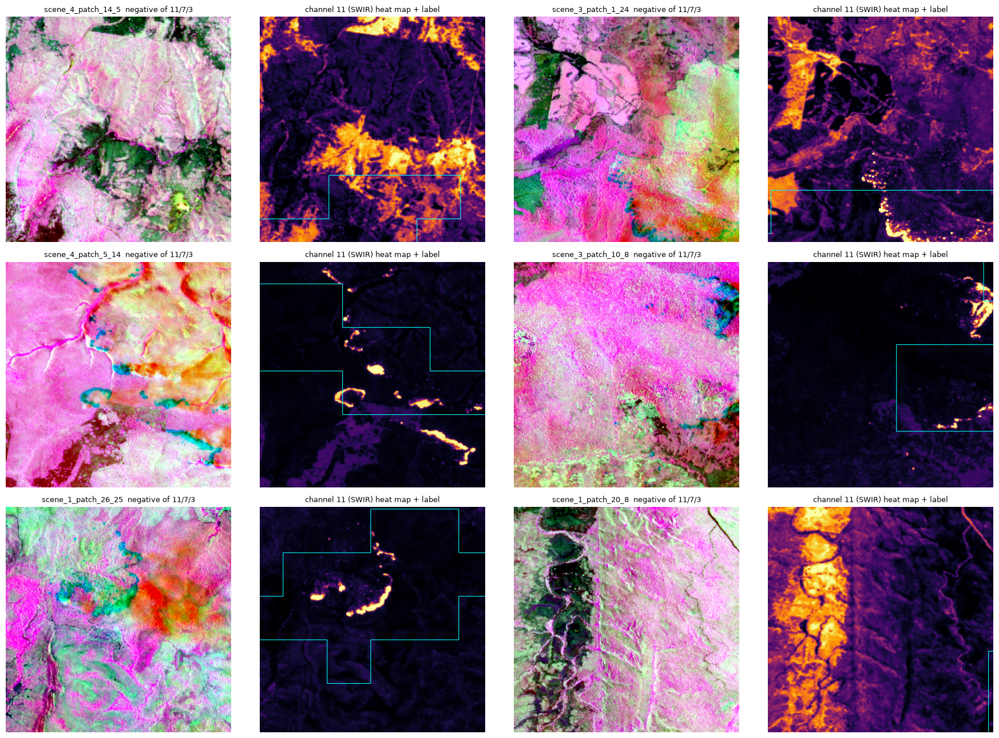

In [16]:
def stretch1(band, lo=2, hi=99.5):
    a, b = np.percentile(band, [lo, hi])
    return np.clip((band - a) / (b - a + 1e-6), 0, 1)

fig, axes = plt.subplots(3, 4, figsize=(18, 13))
for k, (scene, name, npx) in enumerate(picks):
    with np.load(EXTRACT_DIR / scene / name) as d:
        im = d["image"].astype(np.float32)
        lb = d["label"]
    comp = stretch(np.stack([im[11], im[7], im[3]], axis=-1))
    r, c = k // 2, (k % 2) * 2

    axes[r, c].imshow(1.0 - comp)
    axes[r, c].set_title(f"{name[:-4]}  negative of 11/7/3", fontsize=9)

    axes[r, c + 1].imshow(stretch1(im[11]), cmap="inferno")
    axes[r, c + 1].contour(lb, levels=[0.5], colors="cyan", linewidths=0.8)
    axes[r, c + 1].set_title("channel 11 (SWIR) heat map + label", fontsize=9)

for a in axes.ravel():
    a.axis("off")
plt.tight_layout(); plt.show()

In [17]:
thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.8]
tp = np.zeros(len(thresholds)); fp = np.zeros(len(thresholds))
pos = neg = 0

for scene, name, npx in sample:
    with np.load(EXTRACT_DIR / scene / name) as d:
        b12 = d["image"][11].astype(np.float32) / 10000.0
        lb = d["label"] > 0
    pos += int(lb.sum()); neg += int((~lb).sum())
    for i, t in enumerate(thresholds):
        hot = b12 > t
        tp[i] += (hot & lb).sum()
        fp[i] += (hot & ~lb).sum()

print(f"label pixels: {pos:,}   non-label pixels: {neg:,}")
print(f"\n{'thr':>5} {'recall':>8} {'false-pos rate':>15} {'precision':>10} {'IoU':>7}")
for i, t in enumerate(thresholds):
    recall = tp[i] / pos
    fpr = fp[i] / neg
    prec = tp[i] / max(tp[i] + fp[i], 1)
    iou = tp[i] / (pos + fp[i])
    print(f"{t:5.1f} {recall:8.3f} {fpr:15.3f} {prec:10.3f} {iou:7.3f}")

label pixels: 3,484,151   non-label pixels: 12,244,489

  thr   recall  false-pos rate  precision     IoU
  0.2    0.150           0.249      0.146   0.080
  0.3    0.055           0.102      0.134   0.041
  0.4    0.017           0.012      0.282   0.016
  0.5    0.013           0.002      0.660   0.012
  0.6    0.011           0.001      0.696   0.011
  0.8    0.009           0.001      0.699   0.008


scene_3_patch_10_10    median ratio=0.65 | p99 ratio=0.84 | median ratio at brightest 0.5% B12=0.80
scene_3_patch_10_2     median ratio=0.73 | p99 ratio=1.01 | median ratio at brightest 0.5% B12=0.83
scene_3_patch_10_3     median ratio=0.72 | p99 ratio=2.75 | median ratio at brightest 0.5% B12=2.63
scene_3_patch_10_32    median ratio=0.70 | p99 ratio=0.94 | median ratio at brightest 0.5% B12=0.81
scene_3_patch_10_33    median ratio=0.70 | p99 ratio=0.96 | median ratio at brightest 0.5% B12=0.79
scene_3_patch_10_34    median ratio=0.61 | p99 ratio=1.03 | median ratio at brightest 0.5% B12=1.84


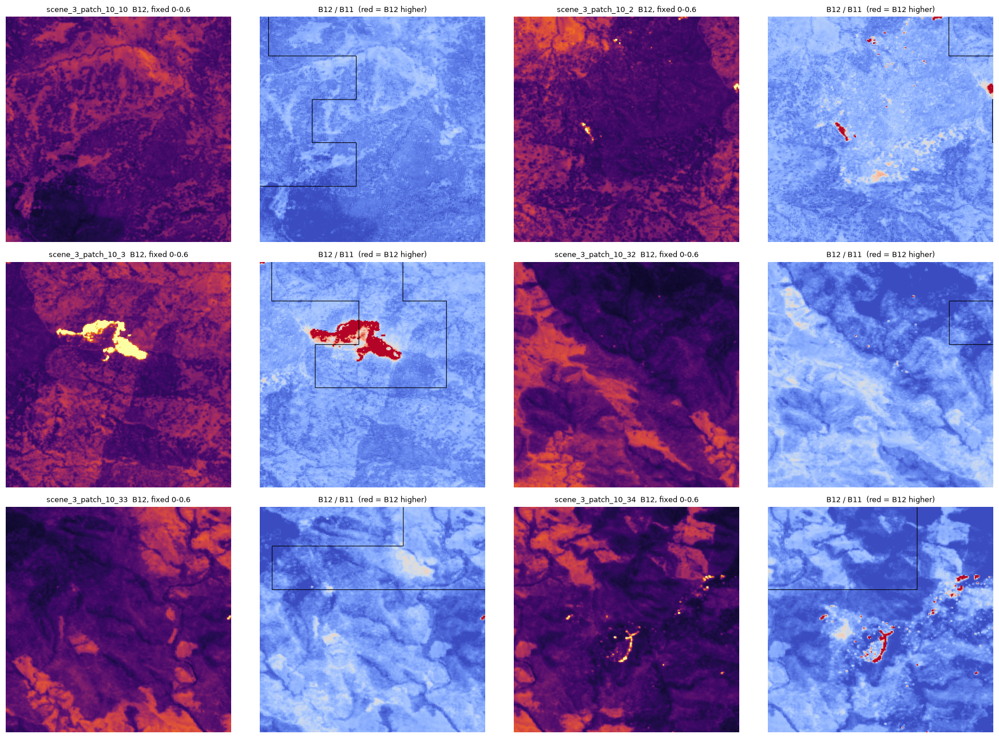

In [18]:
def ratio_view(scene="scene3", start=0, n=6):
    recs = [r for r in fire_records if r[0] == scene][start:start + n]
    fig, axes = plt.subplots(3, 4, figsize=(18, 13))
    for ax in axes.ravel():
        ax.axis("off")

    for k, (sc, name, npx) in enumerate(recs):
        with np.load(EXTRACT_DIR / sc / name) as d:
            im = d["image"].astype(np.float32) / 10000.0
            lb = d["label"]
        b11, b12 = im[10], im[11]
        ratio = np.where(b11 > 0.05, b12 / np.maximum(b11, 1e-6), np.nan)

        r, c = k // 2, (k % 2) * 2
        axes[r, c].imshow(b12, cmap="inferno", vmin=0, vmax=0.6)
        axes[r, c].set_title(f"{name[:-4]}  B12, fixed 0-0.6", fontsize=9)
        axes[r, c + 1].imshow(ratio, cmap="coolwarm", vmin=0.5, vmax=1.5)
        axes[r, c + 1].contour(lb, levels=[0.5], colors="black", linewidths=0.8)
        axes[r, c + 1].set_title("B12 / B11  (red = B12 higher)", fontsize=9)

        bright = b12 >= np.nanpercentile(b12, 99.5)
        print(f"{name[:-4]:22s} median ratio={np.nanmedian(ratio):.2f} | "
              f"p99 ratio={np.nanpercentile(ratio, 99):.2f} | "
              f"median ratio at brightest 0.5% B12={np.nanmedian(ratio[bright]):.2f}")

    plt.tight_layout()
    plt.show()

ratio_view("scene3", start=0, n=6)

In [19]:
T_list = [0.2, 0.3, 0.4]
R_list = [1.0, 1.1, 1.2]
tp = np.zeros((3, 3)); fp = np.zeros((3, 3)); n_hot = np.zeros((3, 3)); pos = 0

for scene, name, npx in sample:
    with np.load(EXTRACT_DIR / scene / name) as d:
        im = d["image"].astype(np.float32) / 10000.0
        lb = d["label"] > 0
    b11, b12 = im[10], im[11]
    ratio = b12 / np.maximum(b11, 1e-6)
    valid = b11 > 0.05
    pos += int(lb.sum())
    for i, t in enumerate(T_list):
        for j, rr in enumerate(R_list):
            hot = valid & (b12 > t) & (ratio > rr)
            n_hot[i, j] += hot.sum()
            tp[i, j] += (hot & lb).sum()
            fp[i, j] += (hot & ~lb).sum()

print(f"label pixels: {pos:,}")
print(f"\n{'B12>':>5} {'ratio>':>7} {'hot px':>9} {'precision':>10} {'recall':>8} {'IoU':>7}")
for i, t in enumerate(T_list):
    for j, rr in enumerate(R_list):
        prec = tp[i, j] / max(n_hot[i, j], 1)
        rec = tp[i, j] / pos
        iou = tp[i, j] / (pos + fp[i, j])
        print(f"{t:5.1f} {rr:7.1f} {int(n_hot[i, j]):9d} {prec:10.3f} {rec:8.3f} {iou:7.3f}")

label pixels: 3,484,151

 B12>  ratio>    hot px  precision   recall     IoU
  0.2     1.0    237821      0.469    0.032   0.031
  0.2     1.1    175777      0.576    0.029   0.028
  0.2     1.2    136408      0.674    0.026   0.026
  0.3     1.0     98398      0.654    0.018   0.018
  0.3     1.1     94969      0.666    0.018   0.018
  0.3     1.2     91434      0.683    0.018   0.018
  0.4     1.0     72792      0.689    0.014   0.014
  0.4     1.1     71784      0.689    0.014   0.014
  0.4     1.2     71036      0.689    0.014   0.014
